# Practical: Data Analysis & Vectors

---

#### **Instructions**: Answer all questions in order. Write clean, commented code. Use Markdown cells for written answers.

---

In [12]:
# import all necessary libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

---

## Q1. Distance Matrix with NumPy Broadcasting

#### You have **3 delivery locations** (group A) and **2 warehouses** (group B), given as 2D coordinates:

```python
A = np.array([[1, 2],
[4, 6],
[7, 1]])

```python
B = np.array([[0, 0],
[5, 5]])

1. Reshape A and B for broadcasting: A_exp = A[:, np.newaxis, :] and B_exp = B[np.newaxis, :, :] . Print both
shapes.
2. Compute the difference diff = A_exp - B_exp . Print its shape.
3. Compute the **Euclidean distance matrix** using places.
np.sqrt(np.sum(diff**2, axis=2)) . Print the result rounded to 2 decimal
4. In a Markdown cell, answer: which warehouse (B0 or B1) is **closer on average** to all delivery locations?

# Answer

In [13]:
A = np.array([[1, 2],
              [4, 6],
              [7, 1]])
B = np.array([[0, 0],
              [5, 5]])

# 1) reshape for broadcasting
A_exp = A[:, np.newaxis, :]   # (3, 1, 2)
B_exp = B[np.newaxis, :, :]   # (1, 2, 2)
print("A_exp shape:", A_exp.shape)
print("B_exp shape:", B_exp.shape)

A_exp shape: (3, 1, 2)
B_exp shape: (1, 2, 2)


In [36]:
# 2) difference 
diff = A_exp - B_exp
print("diff shape:", diff.shape)

diff shape: (3, 2, 2)


In [15]:
# 3) Euclidean distance matrix (rows = deliveries, cols = warehouses)
dist = np.sqrt(np.sum(diff**2, axis=2))
print(np.round(dist, 2))

[[2.24 5.  ]
 [7.21 1.41]
 [7.07 4.47]]


In [16]:
# 4) average distance per warehouse
avg_dist = dist.mean(axis=0)
print("Average distance to B0, B1:", np.round(avg_dist, 2))
print("Closer warehouse: B%d" % np.argmin(avg_dist))

Average distance to B0, B1: [5.51 3.63]
Closer warehouse: B1


#### Answer Q1.4: B1 is closer on average (about 3.63 vs 5.51 for B0). B1 at (5,5) is near the middle of the deliveries, while B0 at the origin is far from (4,6) and (7,1)

---

# **Q2. Given:**

```python
p = [2, 1, -3]
q = [4, -2, 1]

1. Compute `p · q` using four different methods (loop, `np.dot, np.multiply + sum, np.matmul` ).
2. Using the **geometric formula** `p · q = ||p|| × ||q|| × cos(θ)` , compute the angle θ between p and q in both
radians and degrees.
3. Interpret the angle: are the vectors more aligned, perpendicular, or opposing?
4. Now create a vector r that is **guaranteed to be orthogonal** to p (dot product = 0) in 3D. Verify it numerically.

# ANSWER

In [17]:
p = np.array([2, 1, -3])
q = np.array([4, -2, 1])

# 1) four methods
# Method 1: loop
dot_loop = 0
for pi, qi in zip(p, q):
    dot_loop += pi * qi
# Method 2: np.dot
dot_np = np.dot(p, q)
# Method 3: multiply + sum
dot_mul = np.sum(np.multiply(p, q))
# Method 4: matmul
dot_matmul = np.matmul(p, q)
print(dot_loop, dot_np, dot_mul, dot_matmul)

3 3 3 3


In [18]:
# 2) angle from p.q = ||p|| ||q|| cos(theta)
cos_theta = np.dot(p, q) / (np.linalg.norm(p) * np.linalg.norm(q))
theta_rad = np.arccos(cos_theta)
theta_deg = np.degrees(theta_rad)
print(f"cos(theta) = {cos_theta:.4f}")
print(f"theta = {theta_rad:.4f} rad = {theta_deg:.2f} degrees")

cos(theta) = 0.1750
theta = 1.3949 rad = 79.92 degrees


# 3) Interpretation: theta is about 79.9 degrees (acute, cos is small and positive), so the vectors are only very slightly aligned, i.e. almost perpendicular.

In [37]:
# 4) construct orthogonal vector
# Option A: 
r = np.array([-p[1], p[0], 0])
print("r =", r, "| p.r =", np.dot(p, r))

# Option B: 
r2 = np.cross(p, q)
print("r2 =", r2, "| p.r2 =", np.dot(p, r2), "| q.r2 =", np.dot(q, r2))

r = [-1  2  0] | p.r = 0
r2 = [ -5 -14  -8] | p.r2 = 0 | q.r2 = 0


---

# Q3. Given vectors:

```python
u = [3, -4]
v = [-6, 8]

1. Compute the magnitudes of u and v . What is the ratio `||v|| / ||u||` ? What does this ratio tell you?
2. Compute the unit vectors of u and v . What do you notice?
3. Are `u` and `v` parallel? Justify your answer mathematically (do **not** just plot — use the dot product and magnitudes).
4. On a single plot, draw u , v , and the unit vector of u . Add a legend and dashed axes.

# ANSWER

In [20]:
u = np.array([3, -4])
v = np.array([-6, 8])

# 1) magnitudes and ratio
mag_u = np.linalg.norm(u)
mag_v = np.linalg.norm(v)
print("||u|| =", mag_u, " ||v|| =", mag_v, " ratio =", mag_v / mag_u)

||u|| = 5.0  ||v|| = 10.0  ratio = 2.0


### Answer Q3.1: ||u|| = 5, ||v|| = 10, ratio = 2. v is twice as long as u (v = -2u).

In [21]:
# 2) unit vectors
u_hat = u / mag_u
v_hat = v / mag_v
print("u_hat =", u_hat)
print("v_hat =", v_hat)

u_hat = [ 0.6 -0.8]
v_hat = [-0.6  0.8]


### Answer Q3.2: u_hat = [0.6, -0.8] and v_hat = [-0.6, 0.8]. They have length 1 and are exact negatives of each other, so u and v lie on the same line pointing in opposite directions.

In [22]:
# 3) parallel check using dot product and magnitudes
dot_uv = np.dot(u, v)
cos_uv = dot_uv / (mag_u * mag_v)
print("u.v =", dot_uv, "| ||u||*||v|| =", mag_u * mag_v, "| cos(theta) =", cos_uv)

u.v = -50 | ||u||*||v|| = 50.0 | cos(theta) = -1.0


#### Answer Q3.3: u.v = -50 and ||u||·||v|| = 50, so cos(theta) = -1, theta = 180 degrees. |u.v| = ||u||·||v|| holds only for collinear vectors, so u and v are parallel (antiparallel: opposite direction).

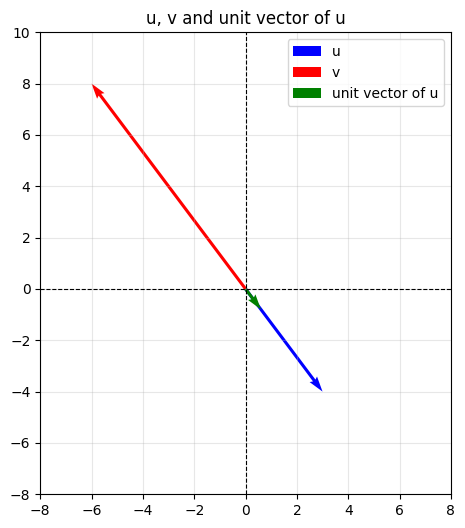

In [23]:
# 4) Plot
plt.figure(figsize=(6, 6))
plt.quiver(0, 0, *u, angles='xy', scale_units='xy', scale=1, color='blue', label='u')
plt.quiver(0, 0, *v, angles='xy', scale_units='xy', scale=1, color='red', label='v')
plt.quiver(0, 0, *u_hat, angles='xy', scale_units='xy', scale=1, color='green', label='unit vector of u')
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlim(-8, 8)
plt.ylim(-8, 10)
plt.gca().set_aspect('equal')
plt.grid(alpha=0.3)
plt.legend()
plt.title('u, v and unit vector of u')
plt.show()

---

# Q4. Pandas: Load, Explore & Clean

### Load the MPG dataset (car fuel efficiency), a dataset built into Seaborn:
```python
df = sns.load_dataset('mpg')


### Each row is a car model. Key columns: `mpg` (miles per gallon), cylinders, weight, horsepower, origin, name .

1. Print the `shape` and display the `first 5 rows`.
2. Print the number of missing values per column. Which column has missing values?
3. Create df_clean by dropping rows with any missing values using .dropna() . Print the new shape.
4. Print basic summary statistics using .describe() . What is the average mpg ?

# ANSWER

In [24]:
# load the dataset
df = sns.load_dataset('mpg')

In [25]:
# 1) shape and first 5 rows
print(df.shape)
df.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [26]:
# 2) missing values per column
print(df.isnull().sum())

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


In [27]:
# 3) drop rows with missing values
df_clean = df.dropna()
print(df_clean.shape)

(392, 9)


In [28]:
# 4) summary statistics
print(df_clean.describe())
print("Average mpg:", round(df_clean['mpg'].mean(), 2))

              mpg   cylinders  displacement  horsepower       weight  \
count  392.000000  392.000000    392.000000  392.000000   392.000000   
mean    23.445918    5.471939    194.411990  104.469388  2977.584184   
std      7.805007    1.705783    104.644004   38.491160   849.402560   
min      9.000000    3.000000     68.000000   46.000000  1613.000000   
25%     17.000000    4.000000    105.000000   75.000000  2225.250000   
50%     22.750000    4.000000    151.000000   93.500000  2803.500000   
75%     29.000000    8.000000    275.750000  126.000000  3614.750000   
max     46.600000    8.000000    455.000000  230.000000  5140.000000   

       acceleration  model_year  
count    392.000000  392.000000  
mean      15.541327   75.979592  
std        2.758864    3.683737  
min        8.000000   70.000000  
25%       13.775000   73.000000  
50%       15.500000   76.000000  
75%       17.025000   79.000000  
max       24.800000   82.000000  
Average mpg: 23.45


# my answeer

# my answeer


- Only horsepower has missing values (6).
- Shape goes from (398, 9) to (392, 9).
- The average mpg is about 23.45.

# Q5. Filtering, Sorting & GroupBy

## Using `df_clean` from Q2:

1. **Filter** cars with `mpg > 30` (fuel-efficient cars). Print how many there are.
2. **Sort** the dataset by `mpg` in descending order and display the top 5 most fuel-efficient cars — show only the columns mpg, cylinders, origin.
3. Use GroupBy to find the average mpg per country of origin ( origin ). Print the result.
4. In one Markdown sentence, state which country produces the most fuel-efficient cars on average.

# ANSWER

In [29]:
# 1) fuel-efficient cars (mpg > 30)
efficient = df_clean[df_clean['mpg'] > 30]
print("Number of cars with mpg > 30:", len(efficient))

Number of cars with mpg > 30: 83


In [30]:
# 2) top 5 most fuel-efficient cars
top5 = df_clean.sort_values('mpg', ascending=False)[['mpg', 'cylinders', 'origin']].head(5)
print(top5)

      mpg  cylinders  origin
322  46.6          4   japan
329  44.6          4   japan
325  44.3          4  europe
394  44.0          4  europe
326  43.4          4  europe


In [31]:
# 3) average mpg per origin
avg_by_origin = df_clean.groupby('origin')['mpg'].mean()
print(avg_by_origin)

origin
europe    27.602941
japan     30.450633
usa       20.033469
Name: mpg, dtype: float64


## Answer Q5.4: Japan produces the most fuel-efficient cars on average (about 30.45 mpg

---

# Q6 Vizualization

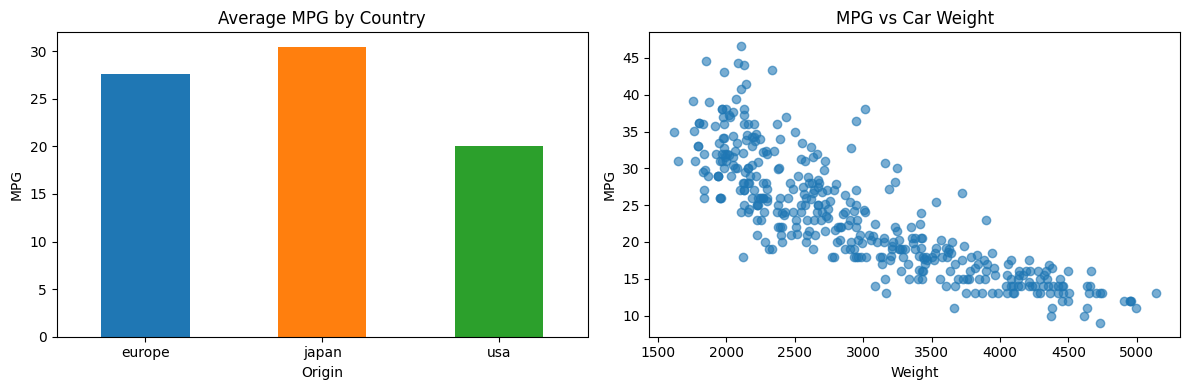

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: bar plot of average mpg per origin
avg_by_origin.plot(kind='bar', ax=axes[0], color=['tab:blue', 'tab:orange', 'tab:green'])
axes[0].set_title('Average MPG by Country')
axes[0].set_xlabel('Origin')
axes[0].set_ylabel('MPG')
axes[0].tick_params(axis='x', rotation=0)

# Right: scatter plot weight vs mpg
axes[1].scatter(df_clean['weight'], df_clean['mpg'], alpha=0.6)
axes[1].set_title('MPG vs Car Weight')
axes[1].set_xlabel('Weight')
axes[1].set_ylabel('MPG')

plt.tight_layout()
plt.show()

#### Observation: There is a clear negative relationship: heavier cars have lower mpg, and the trend is roughly linear (curving slightly at low weights).

---

# Q7 KNN classification on the wine dataset

In [33]:
# 1) load
wine = load_wine()
print("feature_names:", wine.feature_names)
print("target_names:", wine.target_names)
print("data shape:", wine.data.shape)

feature_names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
target_names: ['class_0' 'class_1' 'class_2']
data shape: (178, 13)


In [34]:
# 2) split (75% train, 25% test)
X_train, X_test, y_train, y_test = train_test_split(
    wine.data, wine.target, test_size=0.25, random_state=42)
print(X_train.shape, X_test.shape)

(133, 13) (45, 13)


In [35]:
# 3) train and evaluate
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
print("Test accuracy:", knn.score(X_test, y_test))

Test accuracy: 0.7111111111111111


#### **Answer Q7.4:** This is a classification problem because the target is a discrete class label (one of 3 cultivars), not a continuous number.